# 03 · Random Forest Regressor

**Bài toán:** dự đoán PM2.5 ở giờ kế tiếp (t+1) của cùng một trạm.

Notebook này triển khai Random Forest theo cùng pipeline dữ liệu và **đúng 5 fold thời gian dùng chung với Notebook 02 – Baseline**:
- Dùng lại `load_data`, `add_features`, `time_split`, `cv_folds`, `split_xy` từ `src/`.
- Giữ nguyên mốc chia Test và cách tạo expanding-window `TimeSeriesSplit`, gom các trạm có cùng `target_datetime` vào cùng một phía của fold.
- Tiền xử lý được fit bên trong pipeline trên train của từng fold; validation chỉ dùng để dự đoán và tính metrics.
- Cấu hình Random Forest được cố định trước khi chạy; **không dùng Test để chọn cấu hình, tuning hoặc đánh giá trong notebook này**.

**Đầu ra:** metrics từng fold (MAE, RMSE, R²), thời gian chạy, cấu hình, metadata, OOF predictions, mô hình `.joblib` và 5 biểu đồ PNG trong `outputs/figures/`.

## 1. Cấu hình và nạp thư viện

Tìm thư mục gốc dự án để notebook có thể chạy khi mở từ thư mục `notebooks/` hoặc từ root.

In [13]:
import json
import sys
import time
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

# Tìm thư mục gốc repo (thư mục chứa src/), chạy được từ root hoặc notebooks/.
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [CURRENT_DIR, *CURRENT_DIR.parents] if (path / "src").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (thư mục chứa src/).")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data, time_split, cv_folds, TEST_START
from src.features import (
    FEATURE_COLUMNS,
    FFILL_LIMIT,
    PM25_LAGS,
    ROLLING_WINDOWS,
    add_features,
    build_preprocessor,
    split_xy,
)

RANDOM_STATE = 42
SAVE_ARTIFACTS = True

MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
EXPERIMENT_LOG = PROJECT_ROOT / "experiment_log.csv"

if SAVE_ARTIFACTS:
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Đồng bộ độ phân giải và phong cách lưu hình với Notebook 02 – Baseline.
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

SAVED_FIGURES = []

def save_figure(fig, filename):
    """Lưu biểu đồ PNG vào outputs/figures khi SAVE_ARTIFACTS=True."""
    if SAVE_ARTIFACTS:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        figure_path = FIGURES_DIR / filename
        fig.savefig(figure_path, dpi=150, bbox_inches="tight")
        SAVED_FIGURES.append(figure_path)
        print("Đã lưu hình:", figure_path.relative_to(PROJECT_ROOT))
    return fig

print("Project root:", PROJECT_ROOT)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("Mốc bắt đầu Test:", TEST_START)

Project root: D:\github\sgu_finalproject_machinelearning_2026-2027
scikit-learn: 1.7.2
pandas: 2.3.3
Mốc bắt đầu Test: 2016-09-01 00:00:00


## 2. Nạp dữ liệu và tạo đặc trưng

Đây là cùng quy trình trong Notebook 02. Target được tạo bởi `add_features()` từ PM2.5 của giờ kế tiếp trong cùng trạm. Các dòng thiếu target bị loại bỏ; target không được impute.

In [14]:
raw = load_data()
featured = add_features(raw)
labeled = featured.dropna(subset=["target"]).reset_index(drop=True)

print(f"Dữ liệu gốc: {raw.shape}")
print(f"Dữ liệu sau tạo feature: {featured.shape}")
print(f"Dữ liệu có target: {labeled.shape}")
print(f"Số trạm: {labeled['station'].nunique()}")
print(f"Số feature: {len(FEATURE_COLUMNS)}")

Dữ liệu gốc: (420768, 19)
Dữ liệu sau tạo feature: (420768, 35)
Dữ liệu có target: (412017, 35)
Số trạm: 12
Số feature: 27


## 3. Chia Train/Validation/Test và tạo đúng 5 folds

Dùng chính `time_split()` và `cv_folds()` từ `src/data_loader.py`, giống Notebook 02 – Baseline. `time_split()` dùng `target_datetime` và mốc `TEST_START` trong source; `cv_folds()` tạo expanding-window TimeSeriesSplit và gom tất cả trạm có cùng `target_datetime` vào cùng một phía của fold.

Các kiểm tra xác nhận 5 folds, không trùng hàng, validation luôn nằm sau train và Test bắt đầu đúng mốc. Test chỉ được giữ riêng, không dùng để chọn cấu hình hoặc đánh giá trong notebook này.

In [15]:
# Dùng đúng time_split và cv_folds từ src như Notebook 02.
train_validation, test = time_split(labeled)
train_validation = train_validation.reset_index(drop=True)
test = test.reset_index(drop=True)

X_tv, y_tv = split_xy(train_validation)
folds = cv_folds(train_validation, n_splits=5)

# Bảng thời gian và kích thước của từng fold để đối chiếu với Baseline.
fold_rows = []
for fold_id, (tr, va) in enumerate(folds, start=1):
    train_times = train_validation.iloc[tr]["target_datetime"]
    validation_times = train_validation.iloc[va]["target_datetime"]
    fold_rows.append({
        "fold": fold_id,
        "train_rows": len(tr),
        "validation_rows": len(va),
        "train_start": train_times.min(),
        "train_end": train_times.max(),
        "validation_start": validation_times.min(),
        "validation_end": validation_times.max(),
    })

fold_table = pd.DataFrame(fold_rows)
display(fold_table)

# Các kiểm tra này chỉ xác nhận ranh giới thời gian; không tính metric trên Test.
assert len(folds) == 5, f"Cần đúng 5 folds, hiện có {len(folds)}."
assert train_validation["target_datetime"].max() < TEST_START
assert test["target_datetime"].min() >= TEST_START
for tr, va in folds:
    assert np.intersect1d(tr, va).size == 0, "Train và validation bị trùng hàng."
    assert (
        train_validation.iloc[tr]["target_datetime"].max()
        < train_validation.iloc[va]["target_datetime"].min()
    ), "Fold không bảo đảm validation nằm sau train."

print(f"Train/Validation: {len(train_validation):,} dòng")
print(f"Test: {len(test):,} dòng (được giữ riêng, không dùng để chọn cấu hình/đánh giá)")
print("Kiểm tra mốc thời gian và 5 folds: PASS")

,fold,train_rows,validation_rows,train_start,train_end,validation_start,validation_end
0,1,60258,60595,2013-03-01 01:00:00,2013-09-30 00:00:00,2013-09-30 01:00:00,2014-05-01 17:00:00
1,2,120853,59958,2013-03-01 01:00:00,2014-05-01 17:00:00,2014-05-01 18:00:00,2014-11-30 16:00:00
2,3,180811,59858,2013-03-01 01:00:00,2014-11-30 16:00:00,2014-11-30 17:00:00,2015-07-02 02:00:00
3,4,240669,60217,2013-03-01 01:00:00,2015-07-02 02:00:00,2015-07-02 03:00:00,2016-01-31 14:00:00
4,5,300886,60068,2013-03-01 01:00:00,2016-01-31 14:00:00,2016-01-31 15:00:00,2016-08-31 23:00:00


Train/Validation: 360,954 dòng
Test: 51,063 dòng (được giữ riêng, không dùng để chọn cấu hình/đánh giá)
Kiểm tra mốc thời gian và 5 folds: PASS


## 4. Khởi tạo Random Forest Pipeline

Random Forest không cần StandardScaler. Tuy nhiên, vẫn cần median imputation, missing indicators và one-hot encoding. `build_preprocessor(scale=False)` thực hiện đúng các bước đó; transformer được fit riêng trên train của từng fold.

In [16]:
RF_PARAMS = {
    "n_estimators": 20,
    "max_features": 0.7,
    "max_depth": 16,
    "min_samples_leaf": 5,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

def make_random_forest():
    return Pipeline([
        ("prep", build_preprocessor(scale=False)),
        ("model", RandomForestRegressor(**RF_PARAMS)),
    ])

display(pd.Series(RF_PARAMS, name="value").to_frame())

,value
n_estimators,20.0
max_features,0.7
max_depth,16.0
min_samples_leaf,5.0
random_state,42.0
n_jobs,-1.0


## 5. Hàm tính metrics

In [17]:
def regression_metrics(y_true, y_pred):
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
    }

## 6. Huấn luyện và đánh giá 5-fold Cross Validation

Mỗi fold tạo một pipeline mới. Chỉ `X_train` của fold được dùng để fit tiền xử lý và Random Forest; validation chỉ dùng để dự đoán và tính metrics.

In [18]:
fold_results = []
cv_models = []
oof_predictions = []  # Chỉ chứa dự đoán trên validation; không chứa Test.

cv_start_time = time.perf_counter()
for fold_id, (tr, va) in enumerate(folds, start=1):
    X_train, y_train = X_tv.iloc[tr], y_tv.iloc[tr]
    X_val, y_val = X_tv.iloc[va], y_tv.iloc[va]

    model = make_random_forest()
    fold_start_time = time.perf_counter()
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    elapsed = time.perf_counter() - fold_start_time

    metrics = regression_metrics(y_val, predictions)
    fold_results.append({
        "fold": fold_id,
        **metrics,
        "runtime_seconds": float(elapsed),
        "train_rows": int(len(tr)),
        "validation_rows": int(len(va)),
    })
    cv_models.append(model)

    # Lưu thông tin thời gian/trạm cùng dự đoán OOF để phân tích lại.
    oof_part = train_validation.iloc[va][
        ["station", "datetime", "target_datetime"]
    ].reset_index(drop=True).copy()
    oof_part.insert(0, "fold", fold_id)
    oof_part["y_true"] = y_val.to_numpy()
    oof_part["y_pred"] = predictions
    oof_predictions.append(oof_part)

    print(
        f"Fold {fold_id}/5 | "
        f"MAE={metrics['mae']:.4f} | "
        f"RMSE={metrics['rmse']:.4f} | "
        f"R2={metrics['r2']:.4f} | "
        f"Fit + predict={elapsed:.2f}s"
    )

cv_total_runtime_seconds = time.perf_counter() - cv_start_time
rf_cv_metrics = pd.DataFrame(fold_results)[
    ["fold", "mae", "rmse", "r2", "runtime_seconds", "train_rows", "validation_rows"]
]
rf_oof = pd.concat(oof_predictions, ignore_index=True)

print("\nKết quả validation từng fold:")
display(rf_cv_metrics)
print(f"Tổng thời gian 5-fold CV: {cv_total_runtime_seconds:.2f} giây")

Fold 1/5 | MAE=14.9381 | RMSE=29.8863 | R2=0.8925 | Fit + predict=1.93s
Fold 2/5 | MAE=9.1974 | RMSE=16.0491 | R2=0.9493 | Fit + predict=4.57s
Fold 3/5 | MAE=10.1818 | RMSE=18.9940 | R2=0.9310 | Fit + predict=6.47s
Fold 4/5 | MAE=9.7558 | RMSE=18.6389 | R2=0.9596 | Fit + predict=9.05s
Fold 5/5 | MAE=8.5549 | RMSE=17.2853 | R2=0.9221 | Fit + predict=12.01s

Kết quả validation từng fold:


,fold,mae,rmse,r2,runtime_seconds,train_rows,validation_rows
0,1,14.938066,29.886266,0.892544,1.930744,60258,60595
1,2,9.197387,16.049134,0.949266,4.567176,120853,59958
2,3,10.181776,18.994013,0.931021,6.472419,180811,59858
3,4,9.755823,18.638889,0.959637,9.046405,240669,60217
4,5,8.554922,17.285319,0.922102,12.008312,300886,60068


Tổng thời gian 5-fold CV: 34.18 giây


## 7. Tổng hợp kết quả Cross Validation

Báo cáo trung bình và độ lệch chuẩn giữa 5 folds. Các fold có kích thước validation khác nhau; bảng dưới đây trình bày trung bình không trọng số theo fold, tương tự cách tổng hợp trong Notebook 02.

In [19]:
metric_summary_rows = []
for metric in ["mae", "rmse", "r2"]:
    metric_summary_rows.append({
        "metric": metric.upper(),
        "mean": float(rf_cv_metrics[metric].mean()),
        "std": float(rf_cv_metrics[metric].std(ddof=1)),
    })

rf_cv_summary = pd.DataFrame(metric_summary_rows)
display(rf_cv_summary)

print(f"MAE trung bình : {rf_cv_metrics['mae'].mean():.6f}")
print(f"RMSE trung bình: {rf_cv_metrics['rmse'].mean():.6f}")
print(f"R² trung bình  : {rf_cv_metrics['r2'].mean():.6f}")
print(f"Tổng thời gian CV (fit + predict 5 folds): {cv_total_runtime_seconds:.2f} giây")

,metric,mean,std
0,MAE,10.525595,2.541080
1,RMSE,20.170724,5.555088
2,R2,0.930914,0.026037


MAE trung bình : 10.525595
RMSE trung bình: 20.170724
R² trung bình  : 0.930914
Tổng thời gian CV (fit + predict 5 folds): 34.18 giây


## 8. Kiểm tra kết quả Cross-Validation

Bảng dưới đây tổng hợp MAE, RMSE và R² của từng Fold. Phần đánh giá chỉ sử dụng các Fold validation; tập Test chưa được sử dụng.


In [20]:
print("Kết quả đánh giá trên validation theo từng fold:")
display(
    rf_cv_metrics[
        ["fold", "mae", "rmse", "r2", "runtime_seconds", "train_rows", "validation_rows"]
    ]
)

Kết quả đánh giá trên validation theo từng fold:


,fold,mae,rmse,r2,runtime_seconds,train_rows,validation_rows
0,1,14.938066,29.886266,0.892544,1.930744,60258,60595
1,2,9.197387,16.049134,0.949266,4.567176,120853,59958
2,3,10.181776,18.994013,0.931021,6.472419,180811,59858
3,4,9.755823,18.638889,0.959637,9.046405,240669,60217
4,5,8.554922,17.285319,0.922102,12.008312,300886,60068


## 9. Fit mô hình cuối trên toàn bộ Train/Validation

Sau khi hoàn tất CV, fit một pipeline cuối trên toàn bộ Train/Validation để lưu dùng về sau. **Không đánh giá trên Test trong Ngày 2**; Test được giữ nguyên cho giai đoạn đánh giá cuối theo kế hoạch.

In [21]:
final_rf_model = make_random_forest()

final_fit_start = time.perf_counter()
final_rf_model.fit(X_tv, y_tv)
final_fit_seconds = time.perf_counter() - final_fit_start

print(f"Đã fit mô hình cuối trên {len(X_tv):,} dòng Train/Validation.")
print(f"Thời gian fit mô hình cuối: {final_fit_seconds:.2f} giây.")
print("Test chưa được dự đoán, đánh giá hoặc dùng để chọn cấu hình.")

Đã fit mô hình cuối trên 360,954 dòng Train/Validation.
Thời gian fit mô hình cuối: 14.21 giây.
Test chưa được dự đoán, đánh giá hoặc dùng để chọn cấu hình.


## 10. Trực quan hóa và xuất hình PNG

Notebook xuất **5 hình PNG** vào `outputs/figures/`. Bốn hình dùng kết quả validation OOF của 5 folds (RMSE/metrics theo fold, Actual-vs-Predicted, residual); Feature Importance lấy từ mô hình cuối fit trên Train/Validation. Không có biểu đồ nào sử dụng nhãn Test.

Đã lưu hình: outputs\figures\random_forest_cv_rmse_by_fold.png


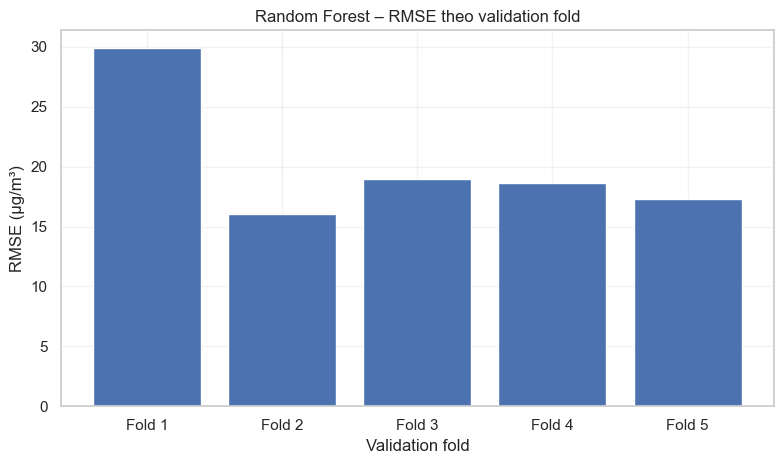

Đã lưu hình: outputs\figures\random_forest_cv_metrics_by_fold.png


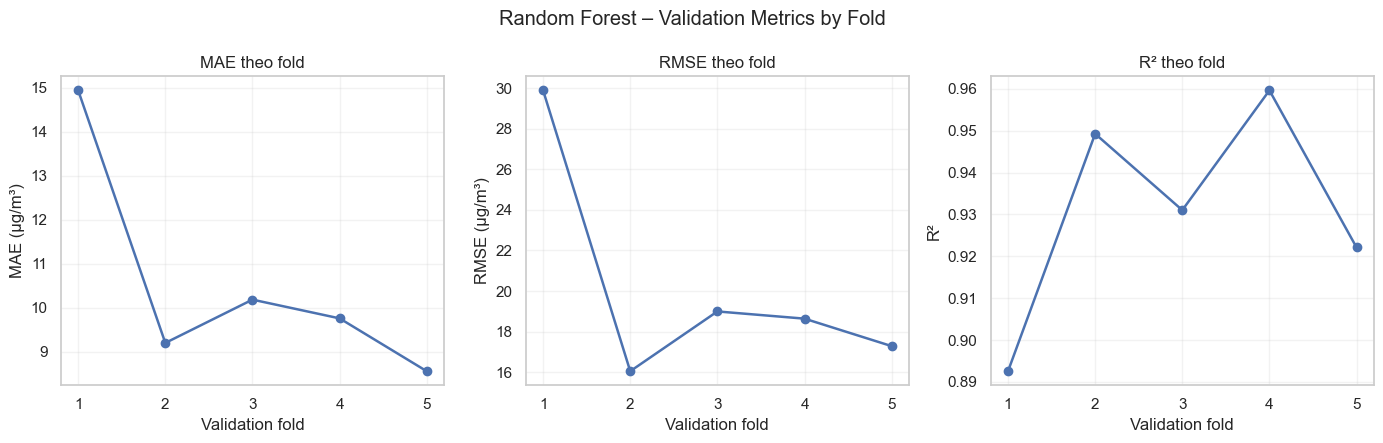

,feature,importance
0,numeric__PM2.5,0.730887
11,numeric__PM2.5_lag_1,0.180531
12,numeric__PM2.5_lag_2,0.036705
1,numeric__PM10,0.025592
13,numeric__PM2.5_lag_3,0.004657
10,numeric__WSPM,0.003642
8,numeric__DEWP,0.001612
4,numeric__CO,0.001364
3,numeric__NO2,0.001315
6,numeric__TEMP,0.001211


Đã lưu hình: outputs\figures\random_forest_feature_importance.png


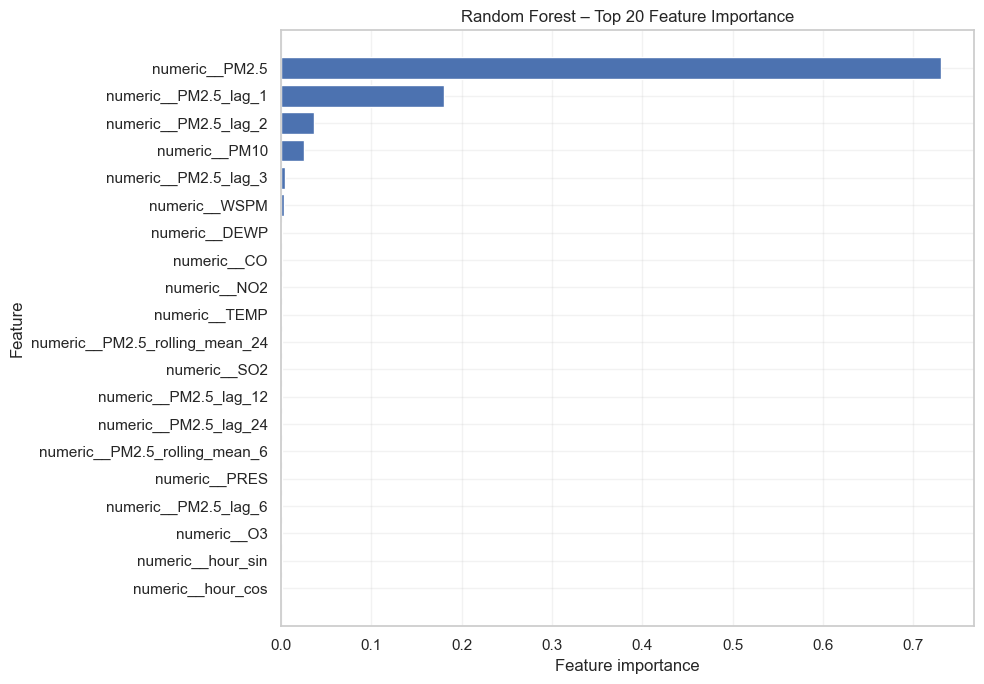

Đã lưu hình: outputs\figures\random_forest_pred_vs_actual.png


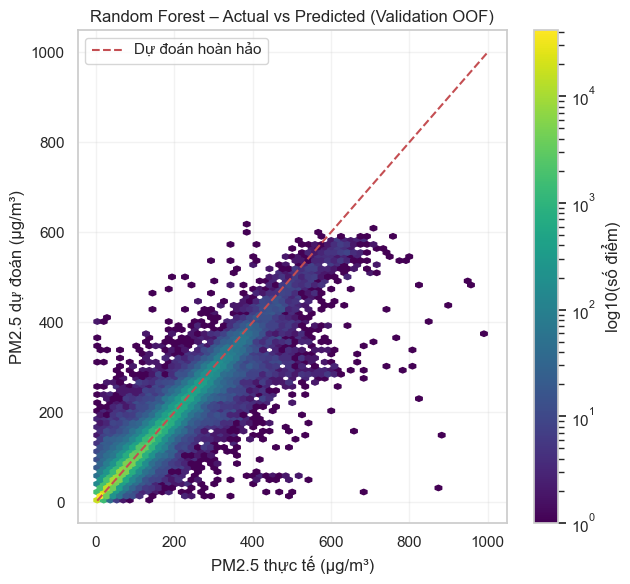

Đã lưu hình: outputs\figures\random_forest_residuals.png


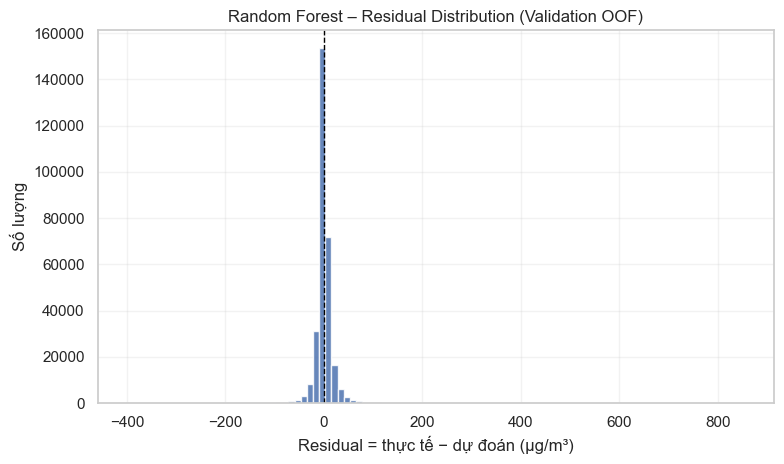

Tổng số dự đoán validation OOF: 300,696
Số hình PNG đã lưu: 5


In [22]:
# 1) RMSE trên từng validation fold.
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(rf_cv_metrics["fold"].astype(str), rf_cv_metrics["rmse"])
ax.set_title("Random Forest – RMSE theo validation fold")
ax.set_xlabel("Validation fold")
ax.set_ylabel("RMSE (µg/m³)")
ax.set_xticks(range(len(rf_cv_metrics)), [f"Fold {x}" for x in rf_cv_metrics["fold"]])
fig.tight_layout()
save_figure(fig, "random_forest_cv_rmse_by_fold.png")
plt.show()
plt.close(fig)

# 2) MAE, RMSE, R² theo fold. Tách 3 trục để không gây hiểu nhầm do khác thang đo.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, metric, title, ylabel in zip(
    axes,
    ["mae", "rmse", "r2"],
    ["MAE theo fold", "RMSE theo fold", "R² theo fold"],
    ["MAE (µg/m³)", "RMSE (µg/m³)", "R²"],
):
    ax.plot(rf_cv_metrics["fold"], rf_cv_metrics[metric], marker="o", linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Validation fold")
    ax.set_ylabel(ylabel)
    ax.set_xticks(rf_cv_metrics["fold"])
fig.suptitle("Random Forest – Validation Metrics by Fold")
fig.tight_layout()
save_figure(fig, "random_forest_cv_metrics_by_fold.png")
plt.show()
plt.close(fig)

# 3) Feature importance từ mô hình cuối fit trên toàn bộ Train/Validation.
prep = final_rf_model.named_steps["prep"]
rf_estimator = final_rf_model.named_steps["model"]
transformed_feature_names = prep.get_feature_names_out()
importance_values = rf_estimator.feature_importances_
if len(transformed_feature_names) != len(importance_values):
    raise ValueError("Số tên feature không khớp số feature importance.")

feature_importance = pd.DataFrame({
    "feature": transformed_feature_names,
    "importance": importance_values,
}).sort_values("importance", ascending=False)
display(feature_importance.head(20))

top_features = feature_importance.head(20).sort_values("importance")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_features["feature"], top_features["importance"])
ax.set_title("Random Forest – Top 20 Feature Importance")
ax.set_xlabel("Feature importance")
ax.set_ylabel("Feature")
fig.tight_layout()
save_figure(fig, "random_forest_feature_importance.png")
plt.show()
plt.close(fig)

# 4) Actual vs Predicted trên validation OOF của cả 5 folds (không dùng Test).
plot_min = float(min(rf_oof["y_true"].min(), rf_oof["y_pred"].min()))
plot_max = float(max(rf_oof["y_true"].max(), rf_oof["y_pred"].max()))
fig, ax = plt.subplots(figsize=(6.5, 6))
hex_plot = ax.hexbin(
    rf_oof["y_true"], rf_oof["y_pred"],
    gridsize=60, bins="log", mincnt=1, cmap="viridis"
)
ax.plot([plot_min, plot_max], [plot_min, plot_max], "r--", linewidth=1.5, label="Dự đoán hoàn hảo")
ax.set_title("Random Forest – Actual vs Predicted (Validation OOF)")
ax.set_xlabel("PM2.5 thực tế (µg/m³)")
ax.set_ylabel("PM2.5 dự đoán (µg/m³)")
fig.colorbar(hex_plot, ax=ax, label="log10(số điểm)")
ax.legend()
fig.tight_layout()
save_figure(fig, "random_forest_pred_vs_actual.png")
plt.show()
plt.close(fig)

# 5) Residual = thực tế - dự đoán trên validation OOF.
rf_oof["residual"] = rf_oof["y_true"] - rf_oof["y_pred"]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(rf_oof["residual"], bins=100, alpha=0.85)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Random Forest – Residual Distribution (Validation OOF)")
ax.set_xlabel("Residual = thực tế − dự đoán (µg/m³)")
ax.set_ylabel("Số lượng")
fig.tight_layout()
save_figure(fig, "random_forest_residuals.png")
plt.show()
plt.close(fig)

print(f"Tổng số dự đoán validation OOF: {len(rf_oof):,}")
print(f"Số hình PNG đã lưu: {len(SAVED_FIGURES)}")

## 11. Lưu mô hình, metrics và Experiment Log


In [23]:
DATASET_VERSION = (
    f"beijing_air_quality_standardized.csv; ffill<={FFILL_LIMIT}h; "
    f"lags={'/'.join(map(str, PM25_LAGS))}; "
    f"rolling={'/'.join(map(str, ROLLING_WINDOWS))}"
)

if SAVE_ARTIFACTS:
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

    model_path = MODELS_DIR / "random_forest.joblib"
    metrics_path = OUTPUTS_DIR / "random_forest_cv_metrics.csv"
    summary_path = OUTPUTS_DIR / "random_forest_cv_summary.csv"
    fold_overview_path = OUTPUTS_DIR / "random_forest_fold_overview.csv"
    oof_path = OUTPUTS_DIR / "random_forest_validation_oof_predictions.csv"
    metadata_path = MODELS_DIR / "random_forest_metadata.json"

    # Lưu mô hình pipeline cuối fit trên toàn bộ Train/Validation.
    joblib.dump(final_rf_model, model_path, compress=3)

    # Lưu metrics chi tiết, summary và thông tin các fold.
    rf_cv_metrics.to_csv(metrics_path, index=False, encoding="utf-8-sig")
    rf_cv_summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
    fold_table.to_csv(fold_overview_path, index=False, encoding="utf-8-sig")
    rf_oof.to_csv(oof_path, index=False, encoding="utf-8-sig")

    metadata = {
        "model": "RandomForestRegressor",
        "pipeline": "build_preprocessor(scale=False) + RandomForestRegressor",
        "created_at": datetime.now().isoformat(timespec="seconds"),
        "python_version": sys.version.split()[0],
        "sklearn_version": sklearn.__version__,
        "pandas_version": pd.__version__,
        "target": "PM2.5 at t+1 (same station)",
        "dataset_version": DATASET_VERSION,
        "train_validation_rows": int(len(X_tv)),
        "train_validation_target_period": [
            str(train_validation["target_datetime"].min()),
            str(train_validation["target_datetime"].max()),
        ],
        "test_start": str(TEST_START),
        "test_rows_reserved": int(len(test)),
        "test_used_for_tuning": False,
        "test_evaluated": False,
        "feature_columns": list(FEATURE_COLUMNS),
        "random_state": RANDOM_STATE,
        "random_forest_params": RF_PARAMS,
        "cv": "TimeSeriesSplit expanding window, 5 folds, grouped by target_datetime; same src.cv_folds as Notebook 02",
        "cv_fold_overview": json.loads(
            fold_table.assign(**{
                column: fold_table[column].astype(str)
                for column in ["train_start", "train_end", "validation_start", "validation_end"]
            }).to_json(orient="records")
        ),
        "cv_fold_metrics": json.loads(rf_cv_metrics.to_json(orient="records")),
        "cv_metrics_mean": {
            metric: float(rf_cv_metrics[metric].mean())
            for metric in ["mae", "rmse", "r2"]
        },
        "cv_metrics_std": {
            metric: float(rf_cv_metrics[metric].std(ddof=1))
            for metric in ["mae", "rmse", "r2"]
        },
        "cv_runtime_seconds": [float(value) for value in rf_cv_metrics["runtime_seconds"]],
        "cv_total_runtime_seconds": float(cv_total_runtime_seconds),
        "final_fit_seconds": float(final_fit_seconds),
        "saved_outputs": {
            "model": str(model_path.relative_to(PROJECT_ROOT)),
            "cv_metrics": str(metrics_path.relative_to(PROJECT_ROOT)),
            "cv_summary": str(summary_path.relative_to(PROJECT_ROOT)),
            "fold_overview": str(fold_overview_path.relative_to(PROJECT_ROOT)),
            "validation_oof_predictions": str(oof_path.relative_to(PROJECT_ROOT)),
            "figures": [path.relative_to(PROJECT_ROOT).as_posix() for path in SAVED_FIGURES],
        },
    }
    metadata_path.write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    # Giữ schema experiment_log.csv tương thích với các dòng Baseline hiện có.
    log_columns = [
        "experiment_id", "model_name", "dataset_version",
        "mae", "rmse", "r2", "notes",
    ]
    log_row = pd.DataFrame([{
        "experiment_id": "random_forest_cv5",
        "model_name": "Random Forest Regressor",
        "dataset_version": DATASET_VERSION,
        "mae": round(float(rf_cv_metrics["mae"].mean()), 6),
        "rmse": round(float(rf_cv_metrics["rmse"].mean()), 6),
        "r2": round(float(rf_cv_metrics["r2"].mean()), 6),
        "notes": (
            "Mean of 5 validation folds; shared expanding-window TimeSeriesSplit; "
            f"CV runtime={cv_total_runtime_seconds:.2f}s; "
            f"final fit={final_fit_seconds:.2f}s; "
            "Test not used for tuning or evaluation."
        ),
    }], columns=log_columns)

    if EXPERIMENT_LOG.exists() and EXPERIMENT_LOG.stat().st_size > 0:
        old_log = pd.read_csv(EXPERIMENT_LOG)
        # Bổ sung các cột nếu log cũ có schema khác, nhưng không làm mất dòng baseline.
        for column in log_columns:
            if column not in old_log.columns:
                old_log[column] = np.nan
        old_log = old_log[old_log["experiment_id"] != "random_forest_cv5"]
        updated_log = pd.concat([old_log, log_row], ignore_index=True, sort=False)
    else:
        updated_log = log_row

    updated_log.to_csv(EXPERIMENT_LOG, index=False, encoding="utf-8-sig")

    print("Đã lưu các đầu ra:")
    for path in [model_path, metrics_path, summary_path, fold_overview_path, oof_path, metadata_path, EXPERIMENT_LOG, *SAVED_FIGURES]:
        print(" -", path.relative_to(PROJECT_ROOT))
else:
    print("SAVE_ARTIFACTS=False: không ghi artifact ra đĩa.")

Đã lưu các đầu ra:
 - models\random_forest.joblib
 - outputs\random_forest_cv_metrics.csv
 - outputs\random_forest_cv_summary.csv
 - outputs\random_forest_fold_overview.csv
 - outputs\random_forest_validation_oof_predictions.csv
 - models\random_forest_metadata.json
 - experiment_log.csv
 - outputs\figures\random_forest_cv_rmse_by_fold.png
 - outputs\figures\random_forest_cv_metrics_by_fold.png
 - outputs\figures\random_forest_feature_importance.png
 - outputs\figures\random_forest_pred_vs_actual.png
 - outputs\figures\random_forest_residuals.png


## 12. Kiểm tra tải lại mô hình

Nạp lại file Joblib và xác nhận dự đoán trên một mẫu Train/Validation trùng với mô hình trong bộ nhớ. Đây chỉ là kiểm tra lưu/tải mô hình, không phải đánh giá Test.

In [24]:
if SAVE_ARTIFACTS:
    reloaded_model = joblib.load(MODELS_DIR / "random_forest.joblib")
    sample_X = X_tv.iloc[: min(1000, len(X_tv))]
    pred_original = final_rf_model.predict(sample_X)
    pred_reloaded = reloaded_model.predict(sample_X)

    assert np.allclose(pred_original, pred_reloaded)
    print("Nạp lại mô hình: PASS")
    print("Kiểu đối tượng:", type(reloaded_model))

Nạp lại mô hình: PASS
Kiểu đối tượng: <class 'sklearn.pipeline.Pipeline'>


## 13. Kết luận và checklist đầu ra

Sau khi chạy hết notebook, kiểm tra các đầu ra:
- `outputs/random_forest_cv_metrics.csv`: MAE, RMSE, R², thời gian chạy và số dòng train/validation của từng fold.
- `outputs/random_forest_cv_summary.csv`: trung bình và độ lệch chuẩn của MAE, RMSE, R².
- `outputs/random_forest_fold_overview.csv`: mốc thời gian và kích thước của 5 folds.
- `outputs/random_forest_validation_oof_predictions.csv`: dự đoán OOF kèm trạm, thời gian, fold, residual; chỉ chứa validation.
- `models/random_forest.joblib` và `models/random_forest_metadata.json`: pipeline, cấu hình, phiên bản thư viện, metrics, thời gian CV/final fit và trạng thái Test.
- `experiment_log.csv`: dòng `random_forest_cv5`, giữ nguyên các dòng Baseline.
- **5 hình PNG** trong `outputs/figures/`:
  1. `random_forest_cv_rmse_by_fold.png`
  2. `random_forest_cv_metrics_by_fold.png`
  3. `random_forest_feature_importance.png`
  4. `random_forest_pred_vs_actual.png`
  5. `random_forest_residuals.png`

**Nguyên tắc đánh giá:** cấu hình Random Forest được cố định trước lượt chạy; chỉ dùng 5 validation folds để báo cáo metrics. Tập Test được tách riêng, không dùng để tuning, chọn cấu hình hoặc đánh giá trong notebook này. Việc đánh giá Test (nếu cần) chỉ thực hiện ở bước đánh giá cuối sau khi nhóm khóa mô hình.

**Phạm vi chưa triển khai tại đây:** Gradient Boosting, RandomizedSearchCV/tuning siêu tham số và đánh giá cuối cùng trên Test.